## ELEC3705 Assignment 1
Oskar Meszaros (z5636164)

### Constants

In [1]:
# imports
from numpy import linalg as LA

import matplotlib.pyplot as plt
import numpy as np

import os

# meta
OUT_DIR = "figures"
try:
    os.mkdir(OUT_DIR)
except:
    pass

# constants
gamma_n = 42.48e6 # Hz
gaussian_std = 10

# Standard vectors and Pauli matrices
d_ket = np.array([0, 1])
u_ket = np.array([1, 0])

sigma_x = np.array([[0, 1], [1, 0]])
sigma_y = np.array([[0, -1j], [1j, 0]])
sigma_z = np.array([[1, 0], [0, -1]])

# Nuclear spin matrices
I_x = sigma_x / 2
I_y = sigma_y / 2
I_z = sigma_z / 2

sigma = np.array([sigma_x, sigma_y, sigma_z])
I_vec = np.array([I_x, I_y, I_z])

# global configuration
plt.rcParams["font.size"] = 18
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["figure.figsize"] = (8, 5.5)
# plt.rcParams["axes.labelsize"] = "large"
plt.rcParams["savefig.dpi"] = 150


### Question 1.1

Rows: 255, Cols: 255


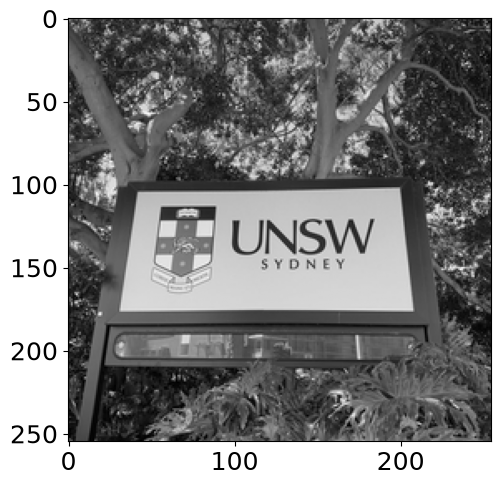

In [2]:
img = plt.imread("image.jpg").astype(float)

plt.imshow(img, cmap="gray")
nrows, ncols = img.shape
print(f"Rows: {nrows}, Cols: {ncols}")
plt.show()

### Question 1.2

 Mu | Column
  0 | 127
 20 | 147


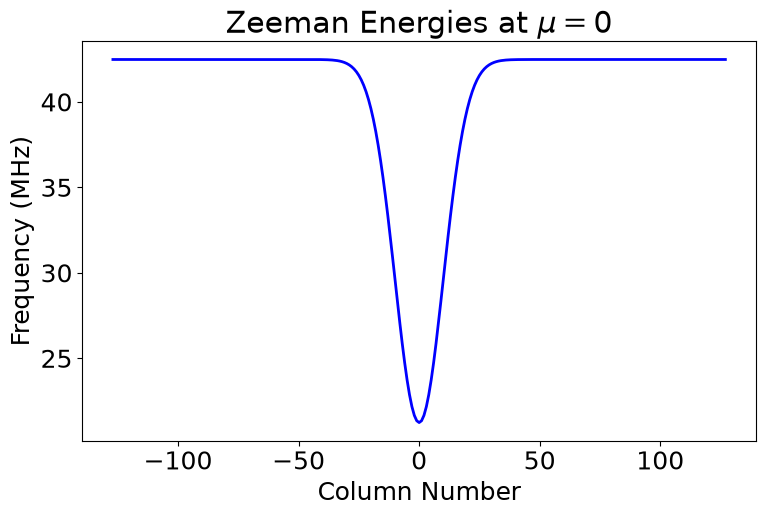

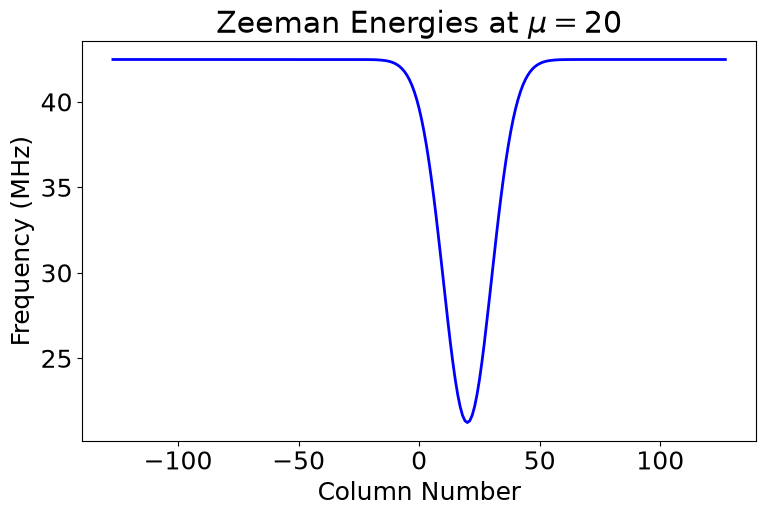

In [3]:
# Time-independent magnetic field B(c) = (0, 0, B_z)
def B_z(c, mu):
    # Gaussian
    G = np.exp(-((c - mu) ** 2) / (2 * gaussian_std**2)) / (
        gaussian_std * np.sqrt(2 * np.pi)
    )
    G_max = G.max()
    # B_z(c)
    return 1 - G / (2 * G_max)


mu_1 = 0
mu_2 = 20

# Columns centred on column 127
c = np.arange(ncols) - ncols // 2

# Create magnetic fields and find Zeeman energy
B1_z = B_z(c, mu_1)
E1_z = gamma_n * B1_z

B2_z = B_z(c, mu_2)
E2_z = gamma_n * B2_z

print(" Mu | Column")
print(f"  0 | {ncols//2}")
print(f" 20 | {ncols//2+20}")

# Plotting
for energies, label, file in zip(
    [E1_z, E2_z], [r"$\mu=0$", r"$\mu=20$"], ["zeeman-mu00.png", "zeeman-mu20.png"]
):
    fig = plt.figure()
    ax = fig.add_subplot()
    ax.plot(c, energies / 1e6, color="blue")
    ax.set_title(f"Zeeman Energies at {label}")
    ax.set_xlabel("Column Number")
    ax.set_ylabel("Frequency (MHz)")
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{file}")


### Question 3

In [4]:
# Total magnetic field (only the time-independent z-component)
B_vec = np.stack([np.zeros(ncols), np.zeros(ncols), B_z(c, 0)], axis=1)
# Construct hamiltonian using Einstein notation because most reliable method I have found
hamiltonian = np.real(gamma_n * np.einsum("ci,ijk->cjk", B_vec, I_vec))

print("Calculated")
print(f"Centre Hamiltonian ({ncols//2}, 0) (Hz):", hamiltonian[ncols // 2], sep="\n") # should be 1/4*gamma_n*sigma_z
print(f"Last Hamiltonian ({ncols-1}, {(ncols-1)-ncols//2}) (Hz):", hamiltonian[ncols - 1], sep="\n")  # should be 1/2*gamma_n*sigma_z
print("\nPredicted")
print(f"Centre Hamiltonian:", 1/4*gamma_n*sigma_z, sep="\n")
print(f"Last Hamiltonian:", 1/2*gamma_n*sigma_z, sep="\n")

Calculated
Centre Hamiltonian (127, 0) (Hz):
[[ 10620000.         0.]
 [        0. -10620000.]]
Last Hamiltonian (254, 127) (Hz):
[[ 21240000.         0.]
 [        0. -21240000.]]

Predicted
Centre Hamiltonian:
[[ 10620000.         0.]
 [        0. -10620000.]]
Last Hamiltonian:
[[ 21240000.         0.]
 [        0. -21240000.]]


### Question 4

In [5]:
B_amp = 0.05 # T
f_drive = gamma_n * 0.5 # gamma_n * B_z(0)
omega_R = gamma_n * B_amp / 2
delta = gamma_n * B1_z - f_drive
H_tilde = delta[:, None, None] * I_z + omega_R * I_x
print(H_tilde[ncols // 2])
print(H_tilde[ncols - 1])

[[     0. 531000.]
 [531000.      0.]]
[[ 10620000.    531000.]
 [   531000. -10620000.]]
